In [ ]:
#pip install -r requirements.txt

In [1]:
import cartopy.crs as ccrs
import copy
import matplotlib.colors as mcolors
import matplotlib.gridspec as gridspec
import matplotlib.pyplot as plt
import networkx as nx 
import numpy as np
import os
import pandas as pd
import seaborn as sns
import sys
import textwrap


from collections import Counter
from IPython.display import IFrame, Image, display
from matplotlib.axes import Axes
from matplotlib.figure import Figure
from networkx.algorithms.community import louvain_communities
from pathlib import Path
from tqdm.notebook import tqdm

In [2]:
sys.path.append(os.getcwd())
sys.path.append(os.path.join(os.getcwd(), 'fuentes_de_datos'))

%load_ext autoreload
%autoreload 2
    
# Módulos nuestros
import funciones_auxiliares as fa
from fuentes_de_datos import conjunto_de_datos as cdd

1. Procesando regiones, subregiones y códigos de países...
Operación finalizada.
2. Procesando ubicaciones...
Operación finalizada.
3. Procesando datos de población...
Operación finalizada.
4. Procesando datos migratorios...
Operación finalizada.
5. Procesando datos económicos...
Operación finalizada.
6. Integrando los datos...
Operación finalizada.


# **Proximidad lingüística y pasado colonial en la *Commonwealth (CW)***

**MIEMBROS**

Durante el período 1990-2024, se sumaron y retiraron países miembros de la asociación:

 - Zimbabwe (se retiró en 2003).
 - Togo (ingresó en 2022).
 - Rwanda (ingresó en 2009).
 - Gabón (ingresó en 2022).
 - Camerún (ingresó en 1995).
 - Mozambique (ingresó en 1995).

**El análisis incluye a los 56 miembros actuales**, aunque no hayan sido parte de la asociación en 1990.

**DATOS MIGRATORIOS**

Trabajamos con el **subconjunto de datos migratorios que tiene a los miembros como origen o destino**. Registramos para cada miembro y en cada año el porcentaje de datos sin origen observable, para tener una noción de la cobertura de los datos. 


**PROXIMIDAD LINGÜÍSTICA**

Utilizamos el **idioma oficial** o **de facto oficial** para definir si dos países/territorios tienen idioma en común. Usamos los datos de localización del CLDR (*Common Locale Data Repository 48.2*) de *Unicode*.

**PASADO COLONIAL**

Según Loft (2023), de los 56 países que son actualmente miembros de la asociación, **solo Rwanda, Mozambique, Gabón y Togo no formaron parte del Imperio Británico**. El estudio de las migraciones desde la proximidad lingüística y el pasado colonial en África, incluye este subconjunto de países. 

Loft, P. (2023, 7 de marzo). The Commonwealth (Research Briefing No. CBP-9478). House of Commons Library. https://researchbriefings.files.parliament.uk/documents/CBP-9478/CBP-9478.pdf


## **Preparación de los datos**

In [3]:
# Lista de miembros de la Mancomunidad de NAciones
LISTA_MIEMBROS_CW = [
    # ÁFRICA
    'BW', 'CM', 'GA', 'GM', 'GH', 'KE', 'SZ', 'LS', 
    'MW', 'MU', 'MZ', 'NA', 'NG', 'RW', 'SC', 'SL',
    'ZA', 'TG', 'UG', 'TZ', 'ZM',
    # ASIA
    'BD', 'BN', 'IN', 'MY', 'MV', 'PK', 'SG', 'LK',
    # AMÉRICA
    'AG', 'BS', 'BB', 'BZ', 'CA', 'DM', 'GD', 'GY', 
    'JM', 'LC', 'KN', 'VC', 'TT',
    # EUROPA
    'CY', 'MT', 'GB',
    # OCEANIA
    'AU',  'FJ', 'KI', 'NR', 'NZ', 'PG', 'WS', 'SB',
    'TO', 'TV', 'VU',
]
CONJ_MIEMBROS_CW = set(LISTA_MIEMBROS_CW)

DICC_NOMBRES_MIEMBROS_CW = {
    p: cdd.df_m49.query('iso2_m49 == @p')['pais_EN'].iloc[0]
    for p in LISTA_MIEMBROS_CW
}

DICC_ISO3_MIEMBROS_CW = {
    p: cdd.df_m49.query('iso2_m49 == @p')['iso3_m49'].iloc[0]
    for p in LISTA_MIEMBROS_CW
}

DICC_NOMBRES_PAISES = {
    p: cdd.df_m49.query('iso2_m49 == @p')['pais_EN'].iloc[0]
    for p in cdd.df_m49['iso2_m49'].unique()
}


# Países que no formaron parte del Imperio Británico
LISTA_NO_IB = ['RW', 'GA', 'MZ', 'TG']

AÑOS = [1990, 1995, 2000, 2005, 2010, 2015, 2020, 2024]

print(len(LISTA_MIEMBROS_CW), 'miembros')

56 miembros


In [4]:
# Diccionario datos sin trazabilidad {país: [x%, ..., x%]} (lista con pct de ZZ por año)
dicc_sin_traza = {} 

# DF con las migraciones por año
df_migras_cw = pd.DataFrame()
for año in AÑOS:
    df_año = cdd.df_migras_90_24.query('año == @año').copy()

    for pais in LISTA_MIEMBROS_CW:
        df_pais = df_año.query('iso2_orig == @pais | iso2_des == @pais').copy()    
        tot_inmigrantes = df_pais.query('iso2_des == @pais').migrantes.sum()
        tot_otros = df_pais.query("iso2_orig == 'ZZ'").migrantes.sum()        
        dicc_sin_traza.setdefault(pais, []).append(round(100*tot_otros/tot_inmigrantes,2))
        
        if len(df_pais) > 0:
            df_migras_cw = pd.concat([df_migras_cw, df_pais])

# Contiene las migraciones desde y hacia países miembros del CW          
df_migras_cw = df_migras_cw.reset_index(drop=True)

### **Cobertura**

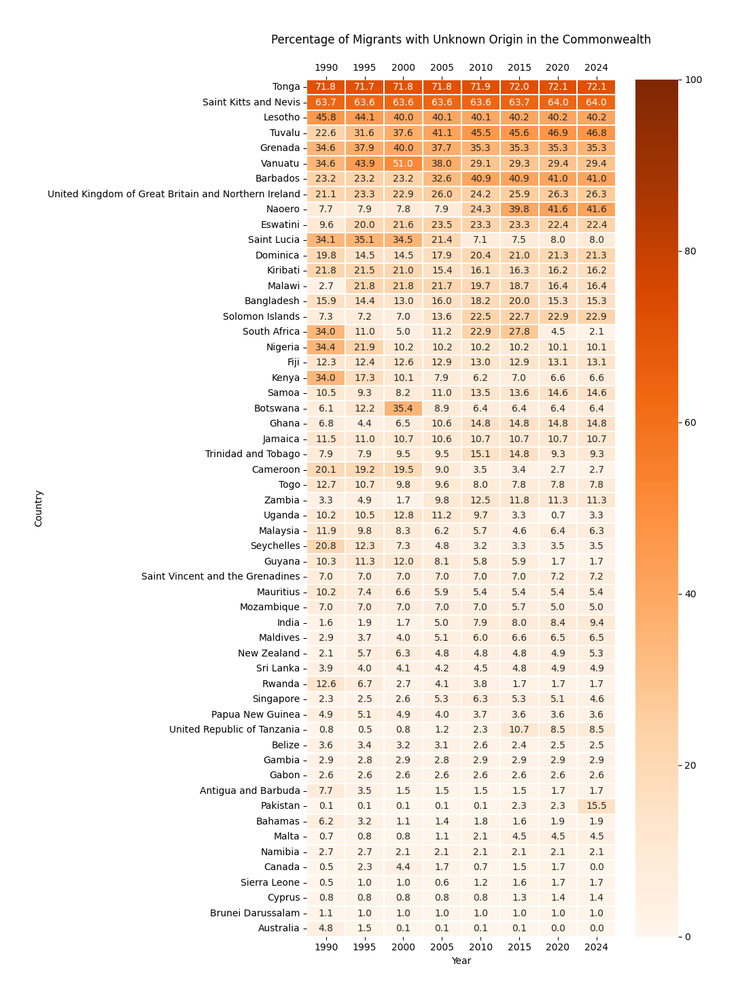

In [5]:
df = pd.DataFrame.from_dict(
    dicc_sin_traza,
    orient='index',
    columns=AÑOS
)

df.index = df.index.map(DICC_NOMBRES_MIEMBROS_CW)

# Ordenar países por porcentaje promedio de datos sin trazabilidad
df = df.loc[df.mean(axis=1).sort_values(ascending=False).index]

plt.figure(figsize=(10, 14))
ax = sns.heatmap(
    df,
    cmap='Oranges',
    vmin=0,
    vmax=100,
    annot=True,
    fmt='.1f',
    linewidths=0.3
)

ax.tick_params(
    axis='x',
    top=True,
    bottom=True,
    labeltop=True,
    labelbottom=True
)

plt.xlabel('Year')
plt.ylabel('Country')
# plt.title('Porcentaje migrantes de origen desconocido en la Commonwealth')
plt.title('Percentage of Migrants with Unknown Origin in the Commonwealth\n')
plt.tight_layout()
plt.show()

### **Idioma en común**

Para agregar a las migraciones si los países de origen y destino comparten idioma oficial o de facto en común, utilizamos los datos de localización del CLDR (*Common Locale Data Repository 48.2*) de *Unicode*.

In [6]:
# Obtenemos los datos de idioma en común entre países
import requests
import xml.etree.ElementTree as ET

url = 'https://raw.githubusercontent.com/unicode-org/cldr/release-48-2/common/supplemental/supplementalData.xml'
xml = requests.get(url)
xml.raise_for_status()
xml.status_code
if xml.status_code == 200:
    raiz = ET.fromstring(xml.text)
    filas = []
    for territorio in raiz.findall('.//territoryInfo/territory'):
        iso2 = territorio.attrib['type']
        for idioma in territorio.findall('languagePopulation'):
            if (
                idioma.attrib.get('officialStatus') == 'official' or
                idioma.attrib.get('officialStatus') == 'de_facto_official' 
            ):
                filas.append({
                    'iso2': iso2,
                    'idioma': idioma.attrib.get('type'),
                    'pct_hablante': idioma.attrib.get('populationPercent'),
                    'status': idioma.attrib.get('officialStatus'),
                })
df_idioma = pd.DataFrame(filas)
# df_idioma.head()

df_idioma_comun = (
    df_idioma.merge(df_idioma, on='idioma')
      .query('iso2_x != iso2_y')
      [['iso2_x', 'iso2_y']]
      .drop_duplicates()
      .rename(columns={
          'iso2_x': 'pais_A',
          'iso2_y': 'pais_B'
      })
)
df_idioma_comun['idioma_en_comun'] = True
# df_idioma_comun.head()

# Agrego columna que indica si el flujo es hacia un territorio con idioma en común
pares_idioma = set(zip(df_idioma_comun['pais_A'], df_idioma_comun['pais_B']))
df_migras_cw['idioma_en_comun'] = [
    p in pares_idioma 
    for p in zip(df_migras_cw['iso2_orig'], df_migras_cw['iso2_des'])
]

### **Migración intra-Commonwealth**

In [7]:
df_migras_cw['migra_intra_cw'] = (
    df_migras_cw['iso2_orig'].isin(CONJ_MIEMBROS_CW) &
    df_migras_cw['iso2_des'].isin(CONJ_MIEMBROS_CW)
)

## **Red de migraciones con origen en la Commonwealth**

In [8]:
# Datos migratorios con origen en países miembros 
df_migras_orig_cw = ( 
    df_migras_cw[df_migras_cw['iso2_orig'].isin(CONJ_MIEMBROS_CW)]
    .copy()
    .reset_index(drop=True)
)

### **Migración y población**

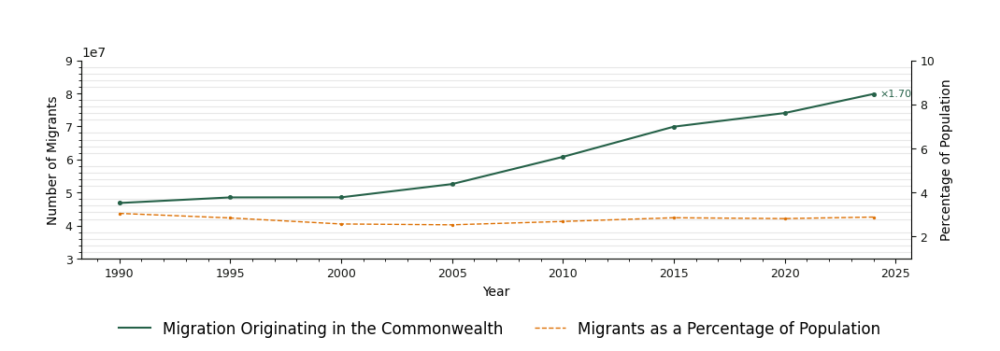

,año,total_migra,total_pobla,pct_pobla_migrante
0,1990,46824773,1534128000,3.052208
1,1995,48514175,1704584000,2.846101
2,2000,48537002,1886801000,2.572449
3,2005,52540929,2073073000,2.534447
4,2010,60775661,2261903000,2.686926
5,2015,69898508,2448568000,2.854669
6,2020,74024176,2628190000,2.816546
7,2024,79790686,2765038000,2.885699


In [9]:
iso3_miembros_cw = DICC_ISO3_MIEMBROS_CW.values()

total_migra = []
total_pobla = []

for año in AÑOS:
    df_año = df_migras_orig_cw.query('año == @año')
    total_migra.append(df_año['migrantes'].sum())
    
    poblacion_total = int(
        cdd.df_poblaciones.loc[
            (cdd.df_poblaciones['iso3_pobla'].isin(iso3_miembros_cw)) &
            (cdd.df_poblaciones['año_pobla'] == año),
            'poblacion'
        ].sum()
    )
    total_pobla.append(poblacion_total)

pct_pobla_migrante = [
    100 * migra/pobla 
    for migra, pobla in zip(total_migra, total_pobla)
]

df_migra_cw_totales = pd.DataFrame({
    'año': AÑOS,
    'total_migra': total_migra,
    'total_pobla': total_pobla,
    'pct_pobla_migrante': pct_pobla_migrante,     
})

dicc_tex_ref = {
    'total_migra': 'Migration Originating in the Commonwealth',#'Migración con origen en la Commonwealth',
    'pct_pobla_migrante': 'Migrants as a Percentage of Population',#'Porcentaje migrante de su población',
}
colores_var = {'total_migra': '#256148', 'pct_pobla_migrante': '#dd7003'}

fig = fa.graficar_comparacion_cw_poblacion(
    df_migra_cw_totales,
    dicc_tex_ref,
    'Number of Migrants',#'Número de migrantes',
    colores_var,
    'migracion_y_poblacion_cw',
)
display(fig)
display(df_migra_cw_totales)

### **Métricas de la red**

,año,nodos,enlaces,density,reciprocity,promedio_in_out_degree,desvio_in_degree,desvio_out_degree
0,1990,180,1733,0.0538,0.2239,9.63,9.89,20.36
1,1995,182,1791,0.0544,0.2189,9.84,10.57,20.53
2,2000,183,1811,0.0544,0.2165,9.90,10.49,20.74
3,2005,183,1845,0.0554,0.2157,10.08,10.84,20.98
4,2010,184,1925,0.0572,0.2068,10.46,11.12,21.55
5,2015,184,2027,0.0602,0.1963,11.02,12.18,21.86
6,2020,184,1998,0.0593,0.1992,10.86,11.55,21.96
7,2024,184,1998,0.0593,0.1992,10.86,11.55,21.95


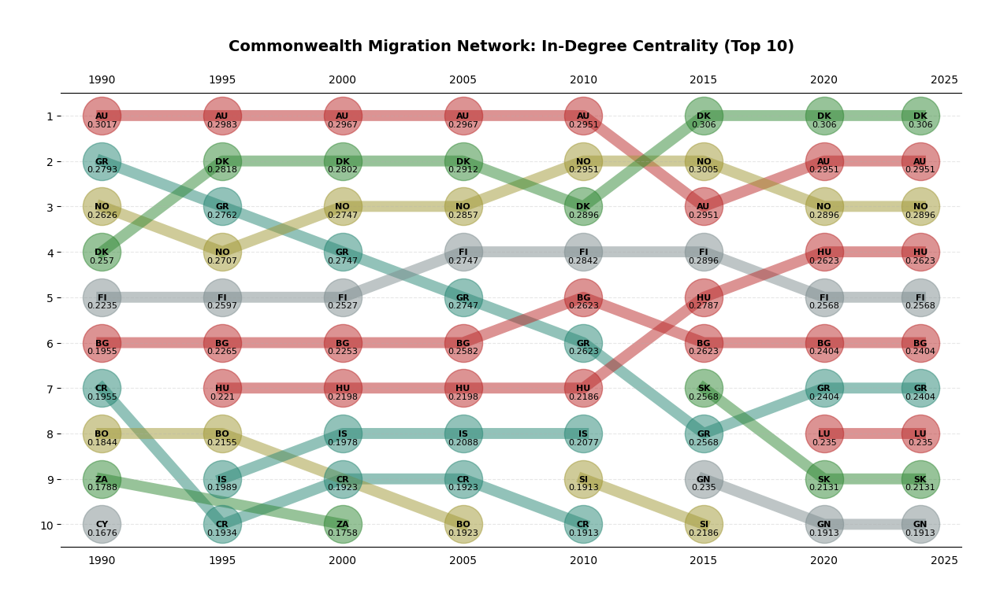

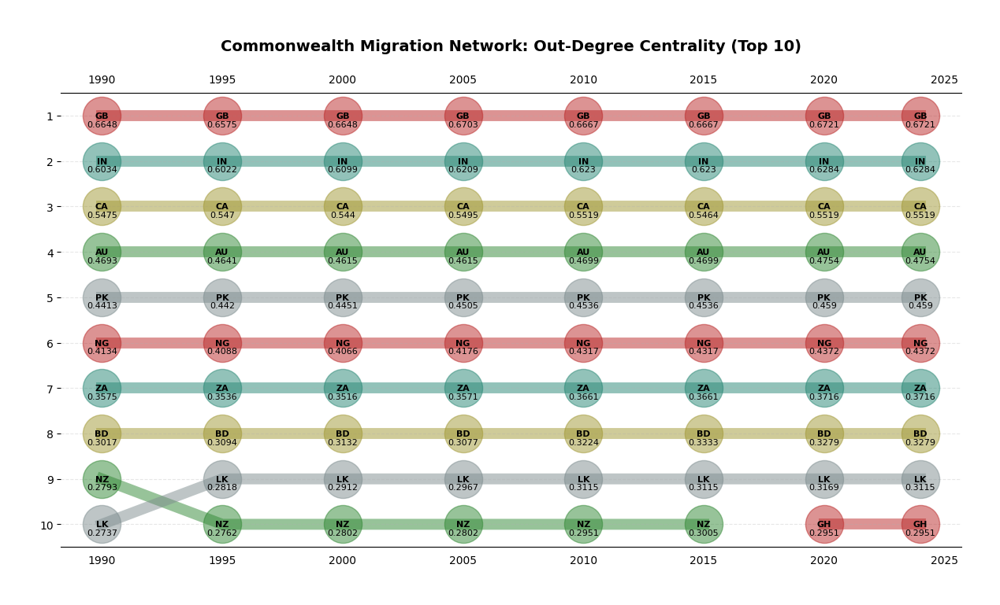

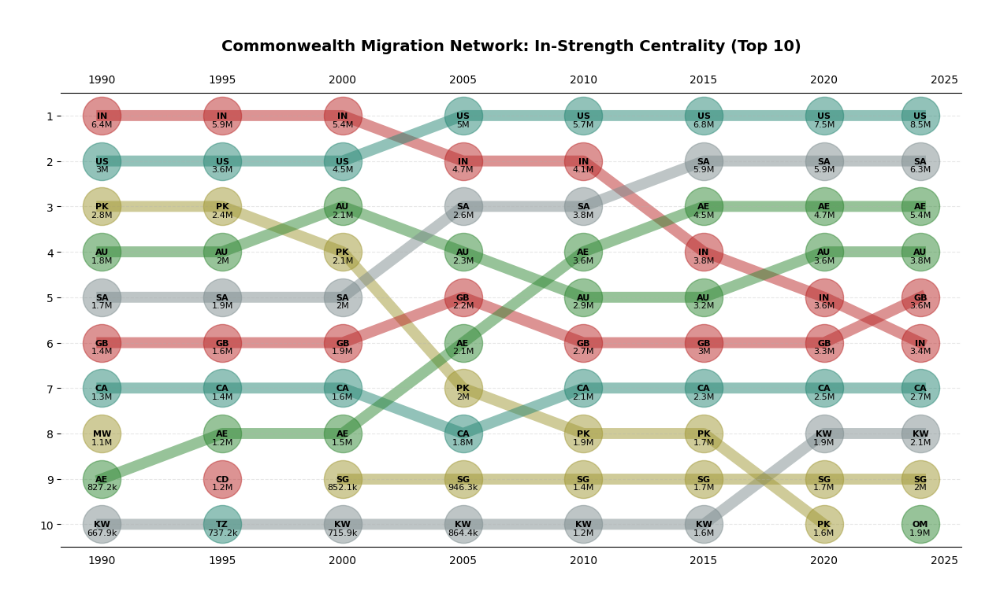

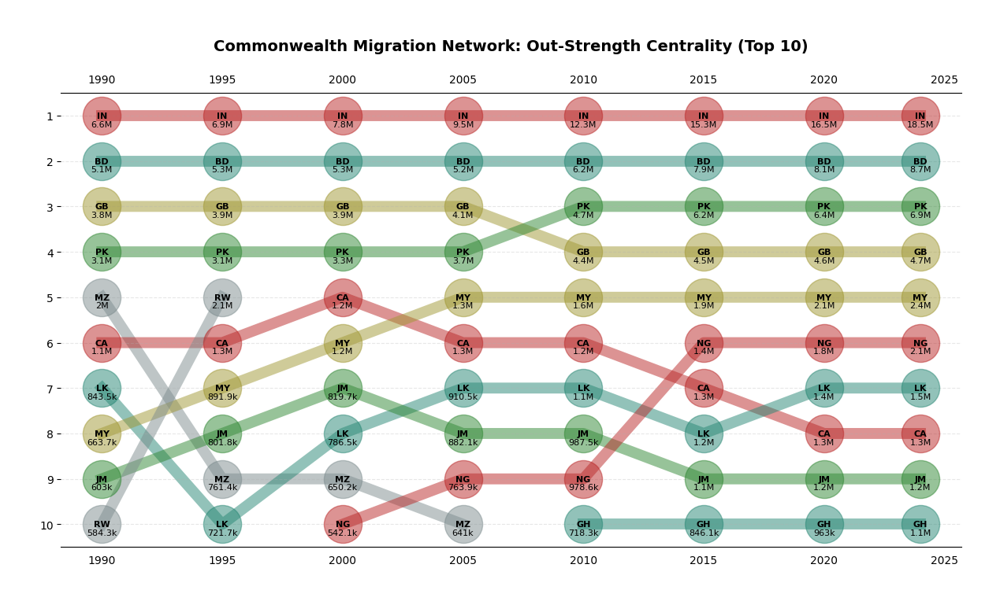

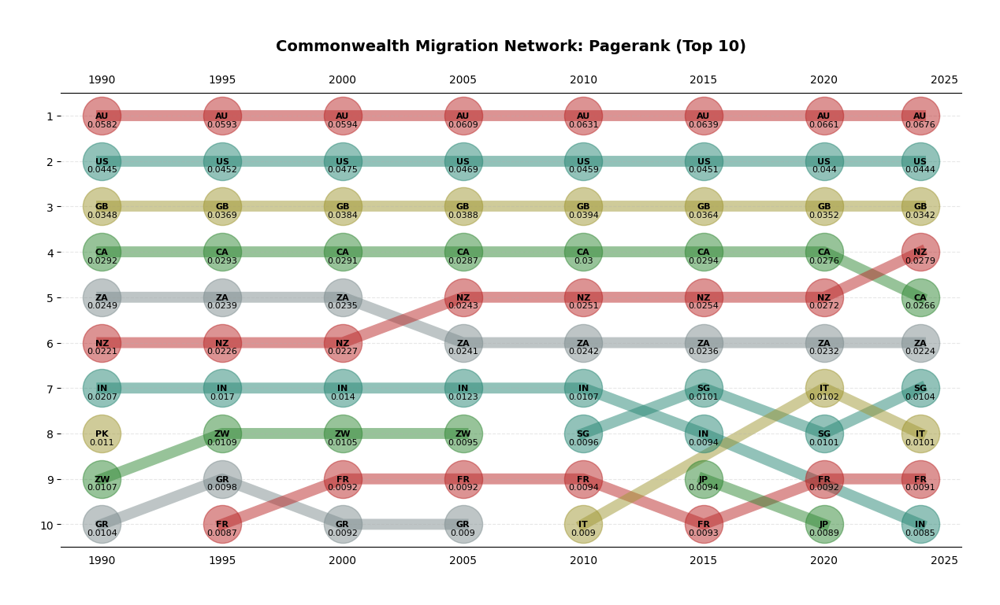

In [24]:
df_metricas = pd.DataFrame() # Uno solo para todo el período
dicc_df_centralidad = {} # Un df por año
for año in AÑOS:
    metricas_cw_mundo, df_top_año  = fa.metricas_red_cw(
        df_migras_orig_cw.query('año == @año').copy(),
        10 # = n_ranking
    ) 
    df = pd.DataFrame([metricas_cw_mundo])    
    df.insert(0, 'año', año)
    
    df_metricas = pd.concat([df_metricas, df])
    
    dicc_df_centralidad[año] = df_top_año
    
df_metricas = df_metricas.reset_index(drop=True)
display(df_metricas)  

centralidades = {
    'cent_in_degree': ('top_10_cent_in_degree', 'cent_in_degree_valor'),
    'cent_out_degree': ('top_10_cent_out_degree', 'cent_out_degree_valor'),    
    'cent_in_strength': ('top_10_cent_in_strength', 'cent_in_strength_valor'),
    'cent_out_strength': ('top_10_cent_out_strength', 'cent_out_strength_valor'),
    'pagerank': ('top_10_pagerank', 'pagerank_valor')
}

resultados = []
for año, df in dicc_df_centralidad.items():
    for metrica, (col_pais, col_valor) in centralidades.items():
        df_temp = df[[col_pais, col_valor]].copy()
        df_temp.columns = ['pais', 'valor']
        df_temp['año'] = año
        df_temp['metrica'] = metrica
        df_temp['ranking'] = range(1, len(df_temp) + 1)
        resultados.append(df_temp)

df_ranking = pd.concat(resultados, ignore_index=True)
df_ranking = df_ranking[['año', 'metrica', 'ranking', 'pais', 'valor']]

nombres_rankings = {
    'cent_in_degree': 'In-Degree Centrality',
    'cent_out_degree': 'Out-Degree Centrality',    
    'cent_in_strength': 'In-Strength Centrality',
    'cent_out_strength': 'Out-Strength Centrality',
    'pagerank': 'Pagerank'
}

metricas_centralidad = df_ranking['metrica'].unique()


args = {
    'paleta_ranking': ['#ba2828', '#278774', '#a19834', '#318834', '#7e8d8f']
} # Por si hace falta ajustar
for metrica in metricas_centralidad:
    if metrica.endswith('strength'):
        convertir_valores = True
    else:
        convertir_valores = False
        
    fig = fa.crear_ranking(
        df_ranking[df_ranking['metrica'] == metrica].copy(),
        10, # Número de posiciones
        True, # Registrar puntuación,
        convertir_valores,
        f'Commonwealth Migration Network: {nombres_rankings[metrica]} (Top 10)\n', # Título
        f'evolución_ranking_{metrica}', # Nombre arhcivo
        **args
    )
    display(fig)

### **Migración recíproca entre países de la Commonwealth**

In [11]:
columnas_a_conservar = ['iso3_orig', 'iso3_des', 'año', 'migrantes']
df_migras_orig_cw_bloques = df_migras_orig_cw[columnas_a_conservar].copy()

# Obtenemos las redes no dirigidas de migración recíproca para cada año
dicc_redes_reciprocas_cw = fa.crear_dicc_redes_reciprocas_por_año(df_migras_orig_cw_bloques, AÑOS)

#### **Coocurrencia en comunidades**

In [12]:
ruta = Path('recursos') # Carpeta donde se guardan las matrices calculadas
nombre_csv_salida = 'df_cooc_red_reciproca_CW' # Se le agrega el año al escribirlo

# Construimos las matrices de coocurrencias en comunidades por año
paises_cw = DICC_ISO3_MIEMBROS_CW.values()

try:
    # Verifico si existen las matrices, que no falta ninguna y las levanto 
    if not ruta.is_dir():
        raise FileNotFoundError('Aún no se calcularon las matrices de coocurrencia.')

    matrices_faltantes = []
    for año in AÑOS:
        archivo = ruta / f"{nombre_csv_salida}_{año}.csv"

        if not archivo.is_file():
            archivos_faltantes.append(str(archivo))
    
    if matrices_faltantes:
        raise FileNotFoundError('Faltan matrices.')
    
    # Levanto los resultados ya guardados
    dicc_cooc_por_año_cw = {}
    for año in AÑOS:
        dicc_cooc_por_año_cw[año] = pd.read_csv(
            ruta / f'{nombre_csv_salida}_{año}.csv',
            index_col=0
        )
    print('Se cargaron las matrices de coocurrencia almacenadas.')
    
except: 
    # Variaciones y parámetros para la detección de comunidades
    semillas = [2, 3, 5, 7, 11, 13, 17, 19, 23, 29, 31, 37, 41, 43, 47, 53, 59, 61, 67, 71]
    resoluciones = [0.2, 0.3, 0.5, 0.7, 1.0, 1.3, 1.5, 1.7, 2.0, 2.3, 2.5, 2.7, 3.0]

    cant_iter_tot = len(semillas) * len(resoluciones) * len(AÑOS)
    peso = 'reciprocidad' # Definida como atributo de las aristas de la redes

    dicc_cooc_por_año_cw = fa.contruir_matrices_coocurrencia_por_año(    
        dicc_redes_reciprocas_cw,
        paises_cw,
        AÑOS,
        semillas,
        resoluciones,
        cant_iter_tot, 
        peso,
        nombre_csv_salida
    )

Se cargaron las matrices de coocurrencia almacenadas.


#### **Bloques de países y cohesión**

Dentro de cada bloque, **los países con nombre en negrita presentaron coocurrencia perfecta en las comunidades**. Los países restantes fueron **asignados al bloque con cuyos miembros coocurrieron la mayoría de las veces**. La aleatoriedad que introduce el método de Louvain puede generar asignaciones distintas de los países en los bordes de cada comunidad.

Promedio cohesión: 0.065
Rango cohesión: 0.001-0.247



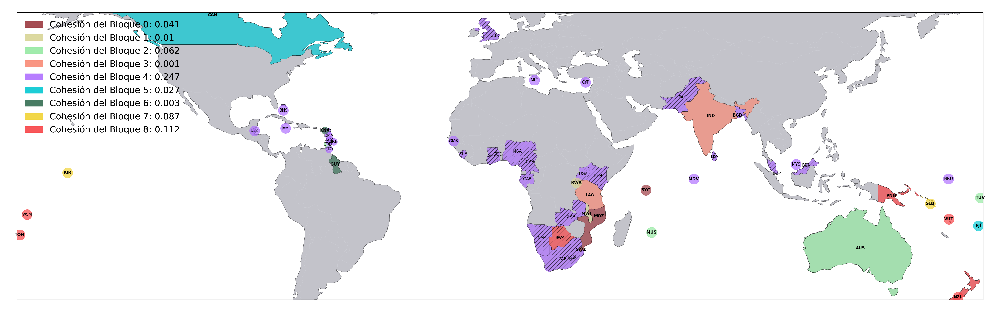


MIEMBROS ESTABLES DE CADA BLOQUE:

Bloque 0 ['Eswatini', 'Seychelles', 'Mozambique']
Bloque 1 ['Rwanda', 'Malawi']
Bloque 2 ['Tuvalu', 'Australia', 'Mauritius']
Bloque 3 ['United Republic of Tanzania', 'India']
Bloque 4 ['Bangladesh', 'Maldives']
Bloque 5 ['Canada', 'Fiji']
Bloque 6 ['Saint Kitts and Nevis', 'Guyana']
Bloque 7 ['Solomon Islands', 'Kiribati']
Bloque 8 ['Tonga', 'Vanuatu', 'Papua New Guinea', 'New Zealand']


BLOQUES CON MIEMBROS ASIGNADOS:

Bloque 0 ['Eswatini', 'Seychelles', 'Mozambique']
Bloque 1 ['Rwanda', 'Malawi']
Bloque 2 ['Tuvalu', 'Australia', 'Mauritius', 'Grenada']
Bloque 3 ['United Republic of Tanzania', 'India']
Bloque 4 ['Singapore', 'Nigeria', 'Cyprus', 'Gabon', 'South Africa', 'Gambia', 'Malaysia', 'United Kingdom of Great Britain and Northern Ireland', 'Cameroon', 'Lesotho', 'Bahamas', 'Dominica', 'Togo', 'Barbados', 'Malta', 'Brunei Darussalam', 'Zambia', 'Sierra Leone', 'Jamaica', 'Antigua and Barbuda', 'Namibia', 'Naoero', 'Uganda', 'Kenya', 'Saint V

In [27]:
# Obtenemos los bloques de países que mantuvieron coocurrencia perfecta durante el período
# y a cada país sin bloque le encontramos el grupo de pertenencia
dicc_bloques_ppales_cw, dicc_bloques_asignados_cw, paises_sin_bloque = (
    fa.obtener_bloques_paises(
        dicc_cooc_por_año_cw,
        AÑOS, 
        paises_cw
    )
)

dicc_invertido = {v:c for c,v in DICC_ISO3_MIEMBROS_CW.items()}
ppales_miembros_bloques = {
    f'Bloque {num_bloque}': [DICC_NOMBRES_MIEMBROS_CW[dicc_invertido[p]] for p in bloque]
    for num_bloque, bloque in dicc_bloques_ppales_cw.items() 
}

miembros_asignados_bloques = {
    f'Bloque {num_bloque}': [DICC_NOMBRES_MIEMBROS_CW[dicc_invertido[p]] for p in bloque]
    for num_bloque, bloque in dicc_bloques_asignados_cw.items() 
}


dicc_cohesion_por_bloque_cw = (
    fa.calcular_cohesion_por_bloque(
        dicc_bloques_asignados_cw,
        df_migras_orig_cw_bloques,
        AÑOS
    )
)

lista_islas_cw = [
    'TON', 'WSM', 'KIR', 'MLT', 'CYP',
    'MUS', 'SYC', 'COM', 'STP', 'CPV',
    'MDV', 'MYS', 'NRU', 'VUT', 'TUV',
    'FJI', 'NZL', 'SLB', 'BHS', 'BLZ',
    'JAM', 'GMB', 'RWA',
]

lista_islas_juntas_cw = ['KNA', 'ATG', 'DMA', 'LCA', 'VCT', 'BRB', 'GRD', 'TTO']

args = {
    'tam_figura': (40,12),
    'margen_lat': 1,
    'margen_lon': 1,
    'loc_ref_cohesion': 'upper left',
    'tam_tex_ref': 26,
}

vis = fa.graficar_bloques(
    paises_sin_bloque,
    dicc_bloques_asignados_cw,
    dicc_cohesion_por_bloque_cw,
    cdd.df_coordenadas.copy(),
    lista_islas_cw,
    lista_islas_juntas_cw,
    'bloques_cw',
    **args
)
display(vis)

print('\nMIEMBROS ESTABLES DE CADA BLOQUE:\n')
for c,v in ppales_miembros_bloques.items():
    print(c,v)

    
print('\n\nBLOQUES CON MIEMBROS ASIGNADOS:\n')
for c,v in miembros_asignados_bloques.items():
    print(c,v)    

### **Migraciones hacia el interior y el exterior de la Commonwealth**

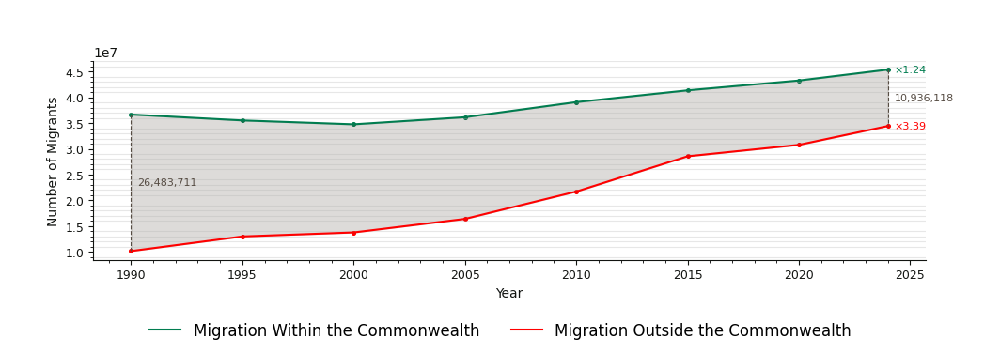

,año,migra_intra,migra_extra
0,1990,36654242,10170531
1,1995,35509212,13004963
2,2000,34755370,13781632
3,2005,36131688,16409241
4,2010,39062500,21713161
5,2015,41344932,28553576
6,2020,43252084,30772092
7,2024,45363402,34427284


In [14]:
# Obtenemos el número de migrantes en cada dirección (intra, extra)
migra_intra_cw = []
migra_extra_cw = []

for año in AÑOS:
    df_año = df_migras_orig_cw.query('año == @año')
    migra_intra_cw.append(df_año.query('migra_intra_cw')['migrantes'].sum())
    migra_extra_cw.append(df_año.query('~migra_intra_cw')['migrantes'].sum())

df_compar_migra_cw = pd.DataFrame({
    'año': AÑOS,
    'migra_intra': migra_intra_cw,
    'migra_extra': migra_extra_cw,
})

dicc_tex_ref = {
    'migra_intra': 'Migration Within the Commonwealth',#'Migración al interior de la Commonwealth',
    'migra_extra': 'Migration Outside the Commonwealth',#'Migración hacia el exterior de la Commonwealth',
}
colores_var = {'migra_intra': '#017d50', 'migra_extra': '#ff0000'}


fig_intra_extra, _ = fa.graficar_comparacion_migra_cw(
    df_compar_migra_cw,
    dicc_tex_ref,
    'Number of Migrants',#'Número de migrantes', # Nombre eje y
    colores_var,
    'migracion_intra_extra_cw',
    **{'color_area': '#554b42'}
)

display(fig_intra_extra)
display(df_compar_migra_cw)

#### **Mapas de las migraciones hacia el exterior y el interior de la Commonwealth 1990-2024**

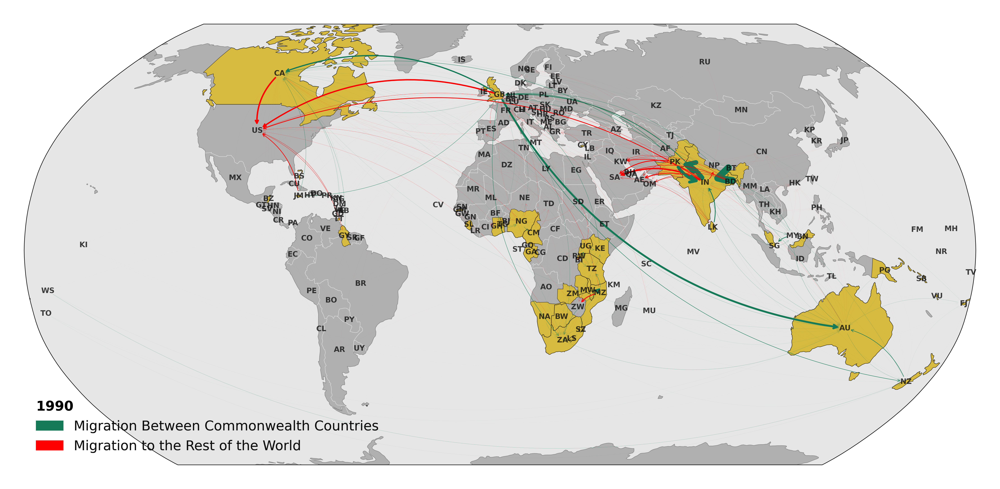

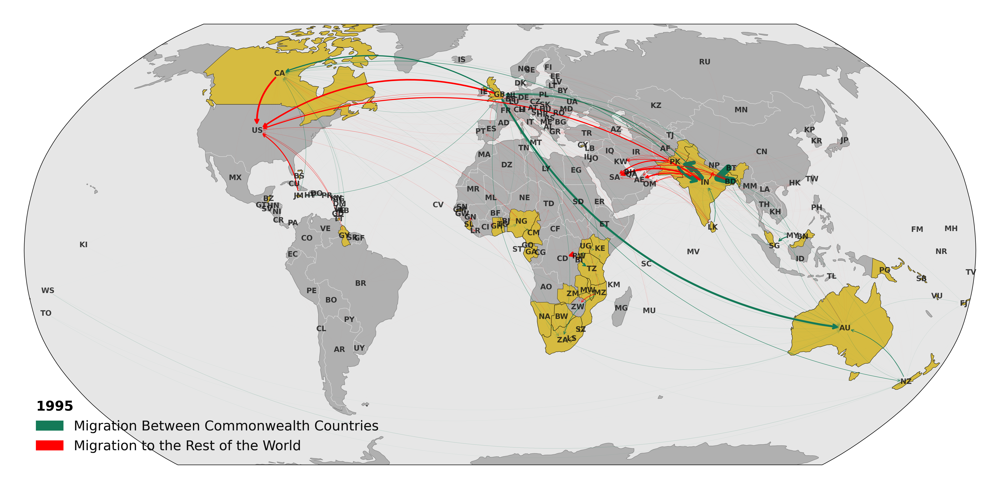

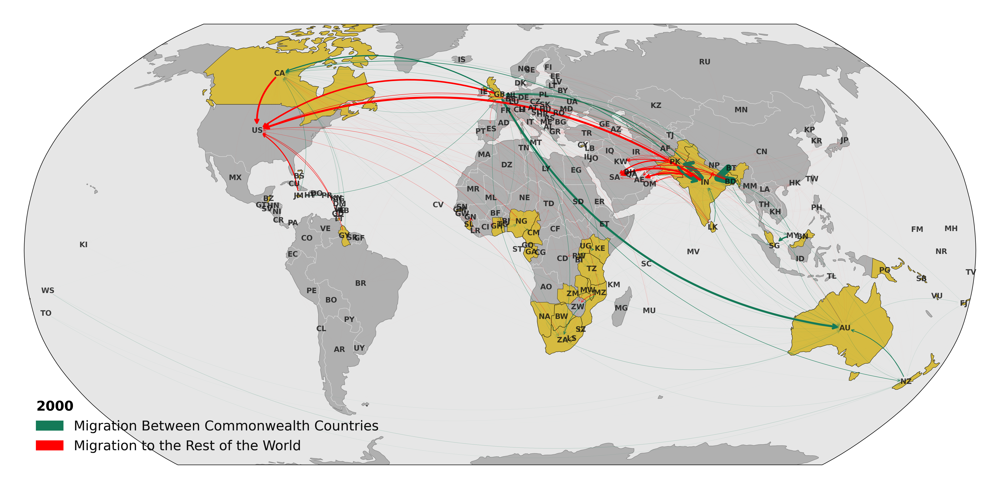

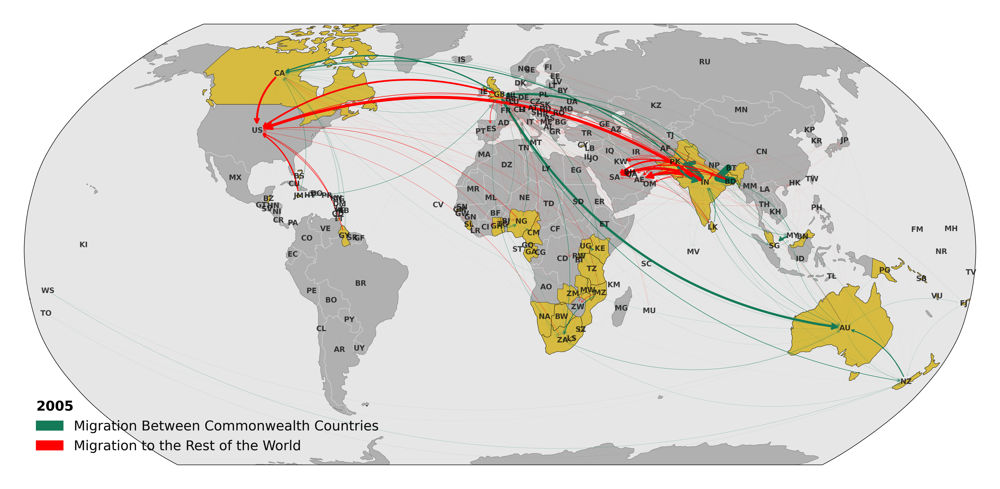

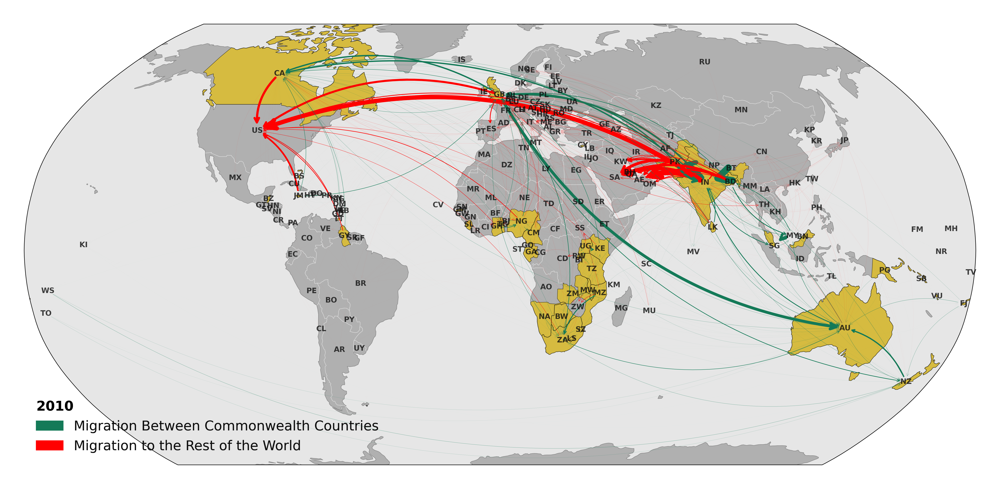

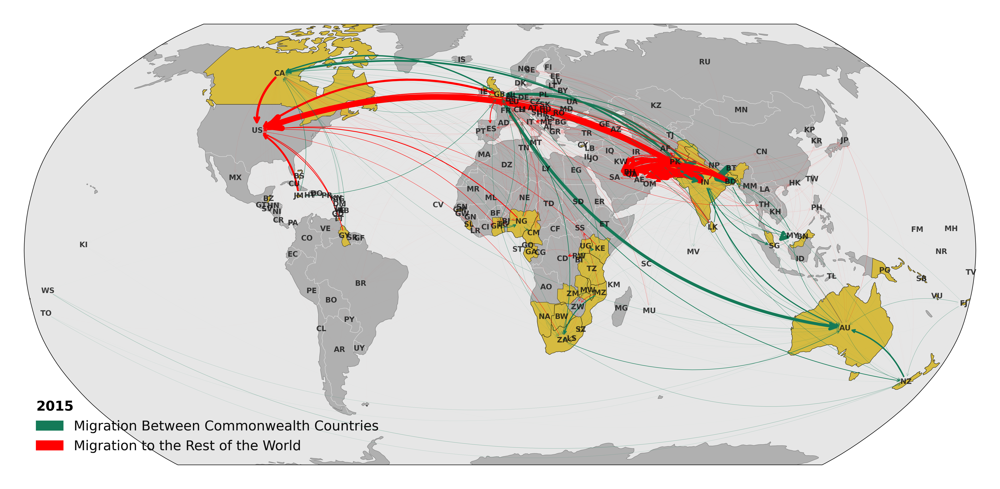

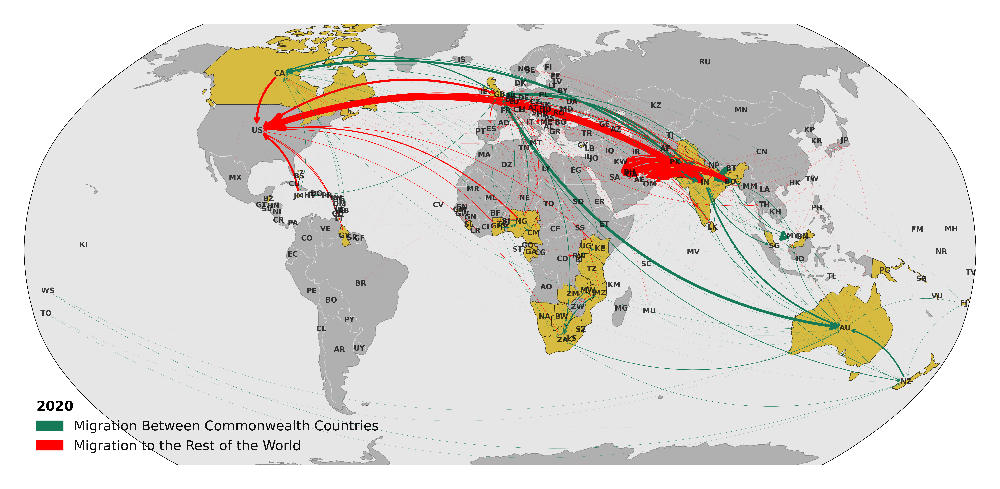

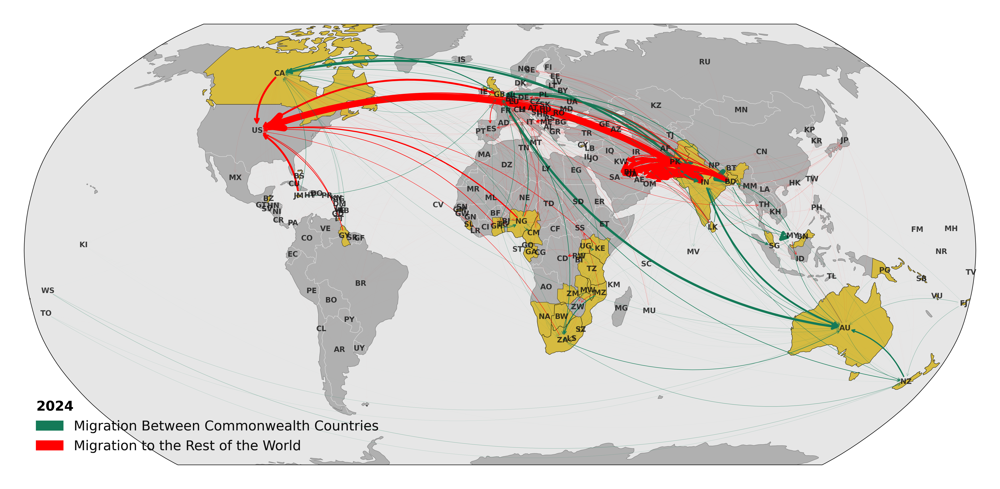

In [15]:
for año in AÑOS: # Permite detectar rapidamente los cambios más importantes
    fig = fa.graficar_red_cw(
        df_migras_orig_cw.query('año == @año'),
        None,
        set(DICC_ISO3_MIEMBROS_CW.values()),
        'migra_intra_cw',
        'Migration Between Commonwealth Countries', # 'Migración entre países de la Commonwealth',
        'Migration to the Rest of the World', # 'Migración hacia el resto del mundo',
        f'red_migra_cw_mundo_{str(año)}', # titulo archivo salida
    )
    display(fig)

#### **Principales destinos fuera de la Commonwealth durante el período 1990-2024**

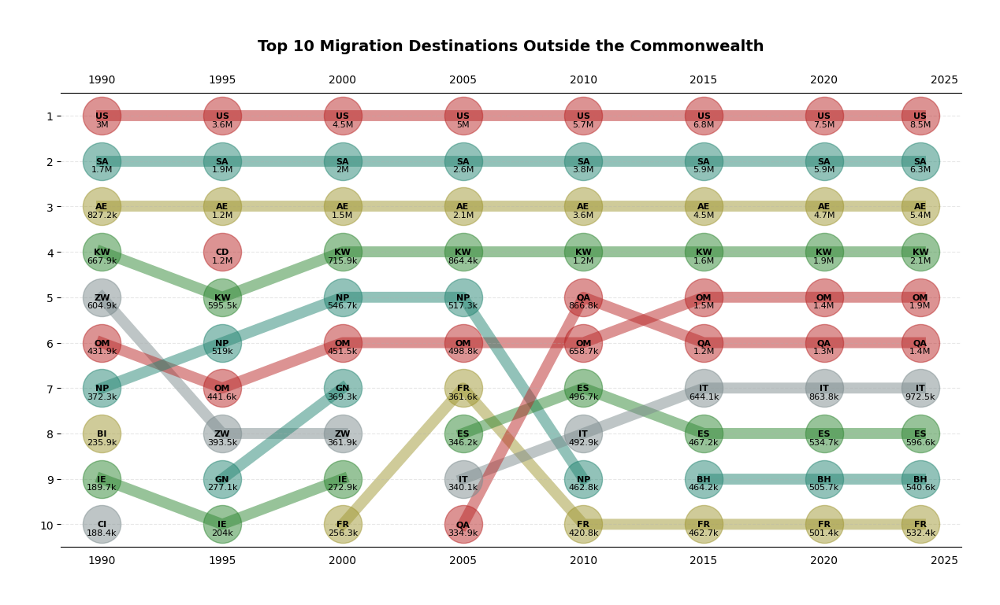

In [25]:
cols = ['año', 'iso2_des', 'migrantes']
df_ppales_destinos_extra_cw = df_migras_orig_cw.query('~migra_intra_cw').copy()[cols]
df_ppales_destinos_extra_cw = (
    df_ppales_destinos_extra_cw.groupby(
        ['año', 'iso2_des'], as_index=False
    )['migrantes'].sum()
).sort_values(['año', 'migrantes'], ascending=[True, False])


df_top10_destinos = df_ppales_destinos_extra_cw.copy()

df_top10_destinos['posicion'] = (
    df_top10_destinos.groupby('año')['migrantes']
    .rank(method='first', ascending=False)
    .astype(int)
)

df_top10_destinos = (
    df_top10_destinos[df_top10_destinos['posicion'] <= 10]
    .sort_values(['año', 'posicion'])
    .reset_index(drop=True)
)

df_top10_destinos['valor'] = df_top10_destinos['migrantes'].map(
    lambda x: fa.convertir_valor(x, 1)
)
df_top10_destinos['categoria'] = 'destinos_extra_cw'

df_top10_destinos = df_top10_destinos[['año', 'categoria', 'posicion', 'iso2_des', 'valor', 'migrantes']] 

args = {'paleta_ranking': ['#ba2828', '#278774', '#a19834', '#318834', '#7e8d8f']}
fig = fa.crear_ranking(
    df_top10_destinos.copy(),
    10, # Número de posiciones
    True, # Registrar puntuación,
    False, # Ya convertí los valores
    'Top 10 Migration Destinations Outside the Commonwealth\n', # Título
    f'evolución_ranking_destinos_externos', # Nombre arhcivo
    **args
)
display(fig)

### **Migraciones entre países con idioma en común**

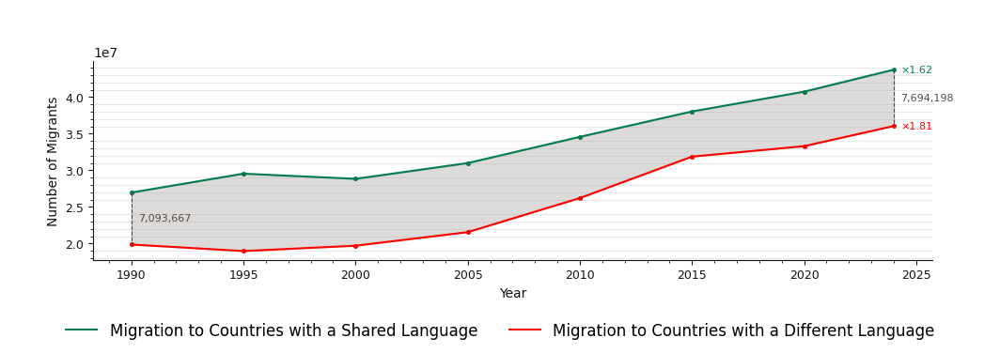

,año,migra_cw_idioma_comun,migra_cw_otro_idioma
0,1990,26959220,19865553
1,1995,29539880,18974295
2,2000,28832598,19704404
3,2005,30985455,21555474
4,2010,34565048,26210613
5,2015,38032065,31866443
6,2020,40732931,33291245
7,2024,43742442,36048244


In [17]:
# Obtenemos el número de migrantes en cada dirección (intra, extra)
migra_cw_idioma_comun = []
migra_cw_otro_idioma = []
for año in AÑOS:
    df_año = df_migras_orig_cw.query('año == @año')
    migra_cw_idioma_comun.append(df_año.query('idioma_en_comun')['migrantes'].sum())
    migra_cw_otro_idioma.append(df_año.query('~idioma_en_comun')['migrantes'].sum())

df_compar_migra_cw_idioma = pd.DataFrame({
    'año': AÑOS,
    'migra_cw_idioma_comun': migra_cw_idioma_comun,
    'migra_cw_otro_idioma': migra_cw_otro_idioma
})

dicc_tex_ref = {
    'migra_cw_idioma_comun': 'Migration to Countries with a Shared Language',#'Migración a países con idioma en común',
    'migra_cw_otro_idioma': 'Migration to Countries with a Different Language',#'Migración a países con distinto idioma'
}
colores_var = {'migra_cw_idioma_comun': '#017d50', 'migra_cw_otro_idioma': '#ff0000'}

fig, eje = fa.graficar_comparacion_migra_cw(
    df_compar_migra_cw_idioma,
    dicc_tex_ref,
    'Number of Migrants',#'Número de migrantes', # Nombre eje y
    colores_var,
    'migracion_intra_cw_idioma',
    **{'color_area': '#554b42'}
)
display(fig)
display(df_compar_migra_cw_idioma)

### **Direcciones de la migración con origen en la Commonwealth**

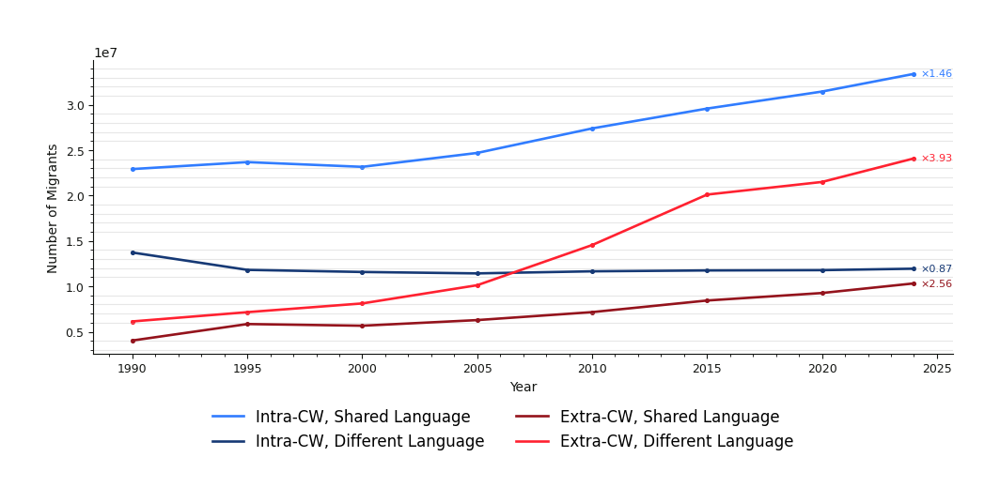

,año,migra_intra_comun,migra_intra_otro,migra_extra_comun,migra_extra_otro,total
0,1990,22925832,13728410,4033388,6137143,46824773
1,1995,23692174,11817038,5847706,7157257,48514175
2,2000,23169914,11585456,5662684,8118948,48537002
3,2005,24702298,11429390,6283157,10126084,52540929
4,2010,27403758,11658742,7161290,14551871,60775661
5,2015,29590810,11754122,8441255,20112321,69898508
6,2020,31465378,11786706,9267553,21504539,74024176
7,2024,33415586,11947816,10326856,24100428,79790686


In [18]:
# Obtenemos el número de migrantes en cada posible dirección 
migra_cw_ic = [] # Intra - idioma comun 
migra_cw_io = [] # Intra - otro idioma  
migra_cw_ec = [] # Extra - idioma comun
migra_cw_eo = [] # Extra - otro idioma

def clasificar_migracion(fila):
    if fila['migra_intra_cw'] and fila['idioma_en_comun']:
        return 'IC'
    elif fila['migra_intra_cw'] and not fila['idioma_en_comun']:
        return 'IO'    
    elif not fila['migra_intra_cw'] and fila['idioma_en_comun']:
        return 'EC'
    else:
        return 'EO'

for año in AÑOS:
    df_año = df_migras_orig_cw.query('año == @año').copy()
    df_año['tipo_migra'] = df_año.apply(clasificar_migracion, axis=1)    
    migra_cw_ic.append(df_año.query("tipo_migra == 'IC'")['migrantes'].sum())
    migra_cw_io.append(df_año.query("tipo_migra == 'IO'")['migrantes'].sum())    
    migra_cw_ec.append(df_año.query("tipo_migra == 'EC'")['migrantes'].sum())
    migra_cw_eo.append(df_año.query("tipo_migra == 'EO'")['migrantes'].sum())

df_compar_direcciones_migra_cw = pd.DataFrame({
    'año': AÑOS,
    'migra_intra_comun': migra_cw_ic,
    'migra_intra_otro': migra_cw_io,
    'migra_extra_comun': migra_cw_ec,
    'migra_extra_otro': migra_cw_eo,
})

df_compar_direcciones_migra_cw['total'] = df_compar_direcciones_migra_cw.iloc[:, 1:].sum(axis=1)

dicc_tex_ref = {
    'migra_intra_comun': 'Intra-CW, Shared Language',#'Migración intra-CW y hacia idioma en común',
    'migra_intra_otro': 'Intra-CW, Different Language',#'Migración intra-CW y hacia distinto idioma',
    'migra_extra_comun': 'Extra-CW, Shared Language',#'Migración extra-CW y hacia idioma en común',
    'migra_extra_otro': 'Extra-CW, Different Language',#'Migración extra-CW y hacia distinto idioma',
}
colores_var = {
    'migra_intra_comun': '#307cff',
    'migra_intra_otro': '#163975',    
    'migra_extra_comun': '#94131c',
    'migra_extra_otro': '#ff2130'
}

fig_intra_extra, _ = fa.graficar_comparacion_migra_direcciones_cw(
    df_compar_direcciones_migra_cw,
    dicc_tex_ref,
    'Number of Migrants',#'Número de migrantes', # Nombre eje y
    colores_var,
    'migracion_direcciones_cw',
    **{'color_area': '#554b42'}
)

display(fig_intra_extra)
display(df_compar_direcciones_migra_cw)

### **Migraciones según idioma en común y pertenencia a la Commonwealth en 1990 y 2024**

{'AE': 'United Arab Emirates', 'AR': 'Argentina', 'AU': 'Australia', 'BD': 'Bangladesh', 'BH': 'Bahrain', 'BI': 'Burundi', 'CA': 'Canada', 'CI': 'Côte d’Ivoire', 'CM': 'Cameroon', 'CN': 'China', 'CY': 'Cyprus', 'FJ': 'Fiji', 'FR': 'France', 'GB': 'United Kingdom of Great Britain and Northern Ireland', 'GH': 'Ghana', 'GR': 'Greece', 'GY': 'Guyana', 'HK': 'China, Hong Kong Special Administrative Region', 'IE': 'Ireland', 'IN': 'India', 'JM': 'Jamaica', 'JP': 'Japan', 'KE': 'Kenya', 'KW': 'Kuwait', 'LB': 'Lebanon', 'LK': 'Sri Lanka', 'LS': 'Lesotho', 'MU': 'Mauritius', 'MW': 'Malawi', 'MY': 'Malaysia', 'MZ': 'Mozambique', 'NG': 'Nigeria', 'NP': 'Nepal', 'NZ': 'New Zealand', 'OM': 'Oman', 'PK': 'Pakistan', 'PT': 'Portugal', 'RU': 'Russian Federation', 'RW': 'Rwanda', 'SA': 'Saudi Arabia', 'SD': 'Sudan', 'SG': 'Singapore', 'TG': 'Togo', 'TT': 'Trinidad and Tobago', 'TZ': 'United Republic of Tanzania', 'UG': 'Uganda', 'US': 'United States of America', 'ZA': 'South Africa', 'ZW': 'Zimbabwe'}.

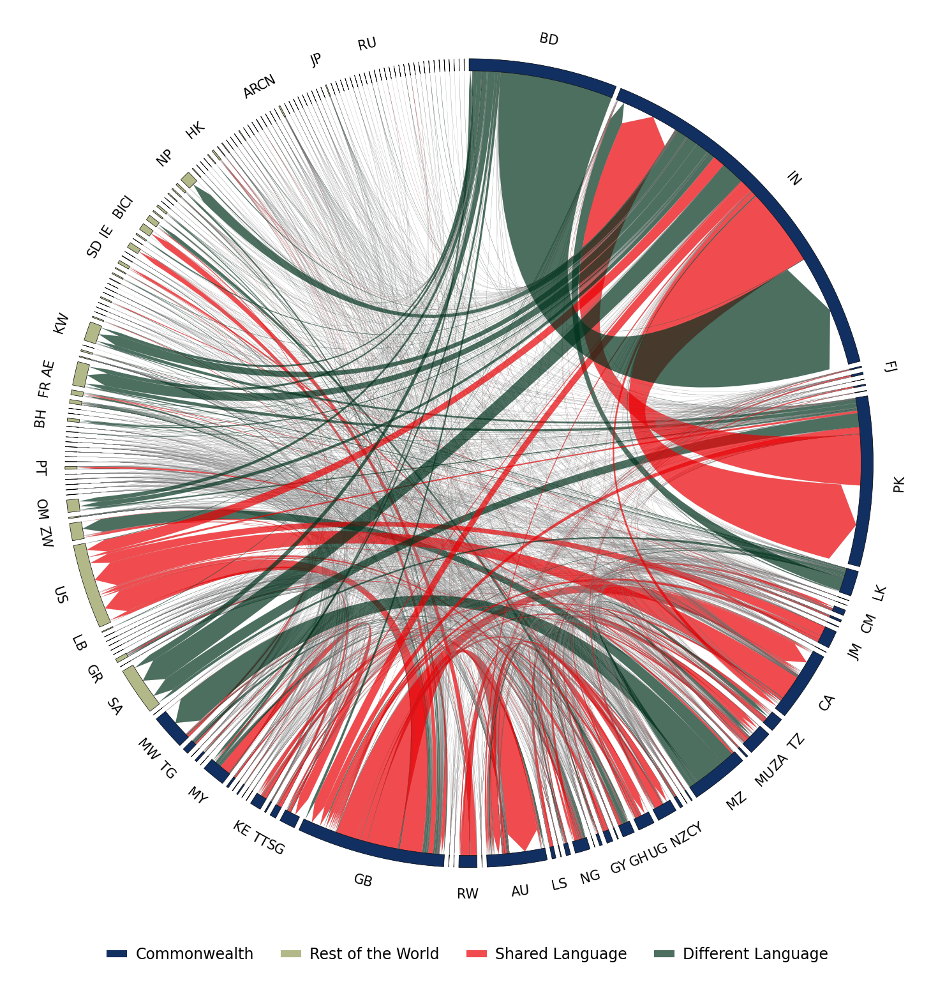

{'AE': 'United Arab Emirates', 'AR': 'Argentina', 'AU': 'Australia', 'BD': 'Bangladesh', 'BH': 'Bahrain', 'BJ': 'Benin', 'BN': 'Brunei Darussalam', 'CA': 'Canada', 'CH': 'Switzerland', 'CM': 'Cameroon', 'CN': 'China', 'DE': 'Germany', 'DK': 'Denmark', 'ES': 'Spain', 'FR': 'France', 'GB': 'United Kingdom of Great Britain and Northern Ireland', 'GH': 'Ghana', 'GR': 'Greece', 'GY': 'Guyana', 'ID': 'Indonesia', 'IE': 'Ireland', 'IN': 'India', 'IT': 'Italy', 'JM': 'Jamaica', 'KE': 'Kenya', 'KW': 'Kuwait', 'LK': 'Sri Lanka', 'MT': 'Malta', 'MU': 'Mauritius', 'MW': 'Malawi', 'MY': 'Malaysia', 'MZ': 'Mozambique', 'NG': 'Nigeria', 'NO': 'Norway', 'NP': 'Nepal', 'NZ': 'New Zealand', 'OM': 'Oman', 'PK': 'Pakistan', 'QA': 'Qatar', 'RW': 'Rwanda', 'SA': 'Saudi Arabia', 'SG': 'Singapore', 'SS': 'South Sudan', 'TG': 'Togo', 'TT': 'Trinidad and Tobago', 'UG': 'Uganda', 'US': 'United States of America', 'ZA': 'South Africa', 'ZW': 'Zimbabwe'}. 2024:


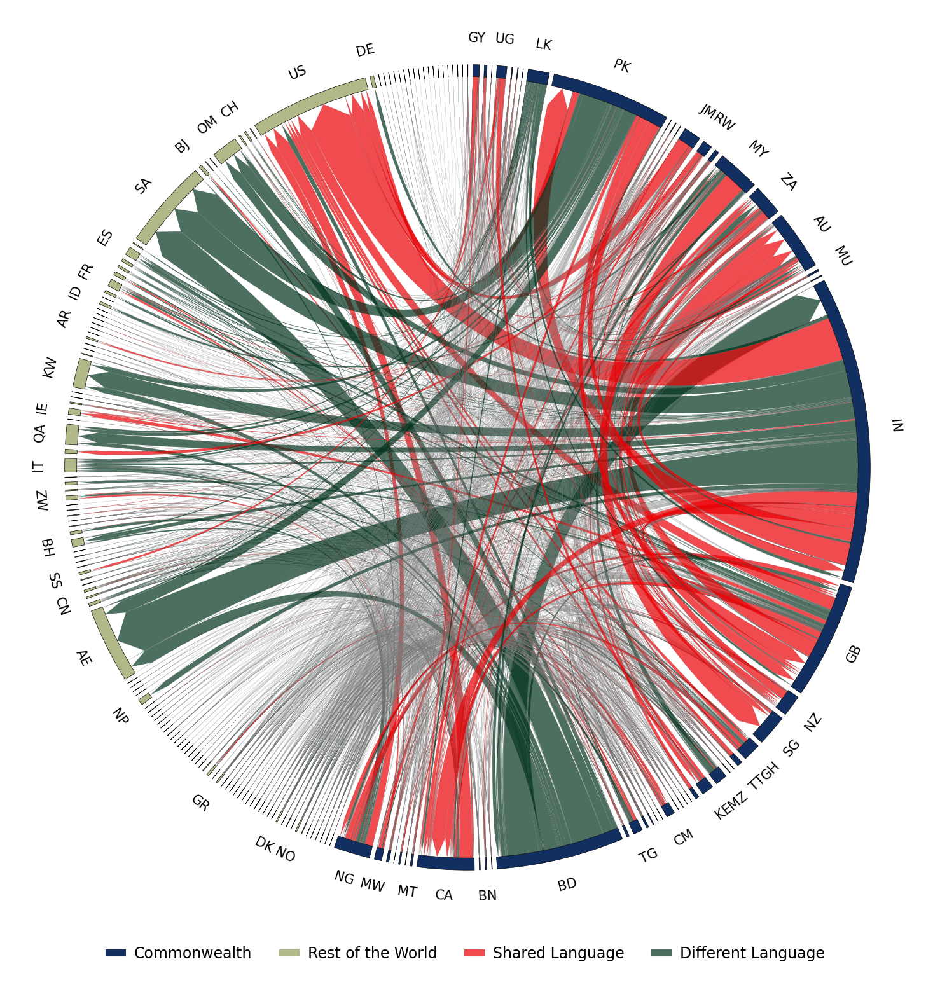

In [22]:
args = {
    'color_nodos_a_destacar': '#122f61',#'#1b458f',
    'color_resto_nodos': '#b3b889',#b4a66c',
    'color_a_idioma_comun': '#eb0004',#004126',#e22739',
    'color_a_otro_idioma': '#00321d'#ff0000'#008b4e',
}

fig_90, paises_visibles_90 = fa.graficar_cuerdas_cw(
    df_migras_orig_cw, # datos
    1990, # año
    (27, 'ppales'), # umbral inicial (27)
    LISTA_MIEMBROS_CW, # nodos a destacar
    'diagrama_cuerdas_migra_cw',
    DICC_NOMBRES_PAISES,
    **args | 
    { # Para manejar con precisión la visibilidad 
        'incluir_pais': [
            'SD', 'IE', 'BI', 'CI', 'FR', 'GR', 'BH', 'PT',
            'CN', 'JP', 'RU', 'HK', 'AR', 'FJ', 'CM',
            'MU', 'CY', 'LB', 'TT', 'LS', 'GY', 'TG'
        ],
        'ocultar_pais': []
    } | 
    {'imprimir_referencias': True}
)

fig_24, paises_visibles_24 = fa.graficar_cuerdas_cw(
    df_migras_orig_cw, # datos
    2024, # año
    (27, 'ppales'), # umbral
    LISTA_MIEMBROS_CW, # nodos a destacar
    'diagrama_cuerdas_migra_cw',
    DICC_NOMBRES_PAISES,
    **args |     
    { # Para manejar con precisión la visibilidad 
        'incluir_pais': [
            'DE', 'GY', 'CH', 'BJ', 'ES', 'FR', 'CN',
            'AR', 'IE', 'ID', 'ZW', 'NP', 'TT', 'GR',
            'BN', 'SS', 'BH', 'DK', 'NO', 'MW', 'MT',
            'MU',
        ],
        'ocultar_pais': []
    } |  
    {'imprimir_referencias': True}
)

# print(paises_visibles_90)
print(f'{paises_visibles_90}. 1990:')
display(fig_90)
print(f'{paises_visibles_24}. 2024:')
display(fig_24)